# Credit Card Fraud Detection — Complete EDA

**Dataset:** Credit Card Fraud Detection (MLG-ULB)  
**Platform:** Kaggle

This notebook covers the complete EDA workflow:
- Dataset download and loading
- Basic inspection
- Missing values and duplicates
- Descriptive statistics
- Class imbalance analysis
- Transaction amount analysis
- Transaction time analysis
- V1–V28 feature distributions
- Correlation analysis
- Outlier analysis
- Fraud vs. legitimate comparisons
- Final EDA summary

> **Note:** Modeling will be performed after EDA so that train/test splitting and imbalance handling can be done without data leakage.

In [45]:
# ============================================================
# 1. DOWNLOAD THE DATASET
# ============================================================

import kagglehub

# Download the latest version of the Credit Card Fraud Detection
# dataset from Kaggle.
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/mlg-ulb/creditcardfraud


In [46]:
# ============================================================
# 2. IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns

# Show all DataFrame columns.
pd.set_option("display.max_columns", None)

# Keep the notebook output readable.
pd.set_option("display.max_rows", 100)

# Clean plotting style.
sns.set_style("whitegrid")

# Default plot size.
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Find and Load the CSV File

In [47]:
# List all files inside the downloaded Kaggle dataset directory.
print("Files in dataset directory:")
print(os.listdir(path))

Files in dataset directory:
['creditcard.csv']


In [48]:
# Build the full path to the CSV file.
csv_path = os.path.join(path, "creditcard.csv")

# Load the CSV file into a Pandas DataFrame.
df = pd.read_csv(csv_path)

print("Dataset successfully loaded!")
print("CSV path:", csv_path)

Dataset successfully loaded!
CSV path: /kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv


## 4. Basic Dataset Inspection

In [5]:
# Display the number of rows and columns.
print("Dataset Shape:")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

Dataset Shape:
Rows    : 284,807
Columns : 31


In [6]:
# Display the first five rows.
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
# Display the last five rows.
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,-1.593105,2.711941,-0.689256,4.626942,-0.924459,1.107641,1.991691,0.510632,-0.682920,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,-0.150189,0.915802,1.214756,-0.675143,1.164931,-0.711757,-0.025693,-1.221179,-1.545556,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,0.411614,0.063119,-0.183699,-0.510602,1.329284,0.140716,0.313502,0.395652,-0.577252,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,-1.933849,-0.962886,-1.042082,0.449624,1.962563,-0.608577,0.509928,1.113981,2.897849,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,-0.915427,-1.040458,-0.031513,-0.188093,-0.084316,0.041333,-0.302620,-0.660377,0.167430,-0.256117,0.382948,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [8]:
# Display all column names.
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [9]:
# Display the data type of every column.
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

In [10]:
# Display detailed information about the DataFrame.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 5. Missing-Value Analysis

In [11]:
# Count missing values in every column.
missing_values = df.isnull().sum()

# Display only columns that contain missing values.
missing_values[missing_values > 0]

Series([], dtype: int64)

In [12]:
# Calculate the total number of missing values.
total_missing = df.isnull().sum().sum()

print(f"Total missing values: {total_missing:,}")

if total_missing == 0:
    print("✓ No missing values found.")
else:
    print("⚠ Missing values detected.")

Total missing values: 0
✓ No missing values found.


## 6. Duplicate Analysis

In [13]:
# Count completely duplicated rows.
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count:,}")

Number of duplicate rows: 1,081


In [14]:
# Calculate the percentage of duplicated rows.
duplicate_percentage = duplicate_count / len(df) * 100

print(f"Duplicate percentage: {duplicate_percentage:.4f}%")

Duplicate percentage: 0.3796%


## 7. Descriptive Statistics

In [15]:
# Generate descriptive statistics for numerical columns.
#
# Includes:
# count, mean, standard deviation, minimum,
# 25th percentile, median, 75th percentile, maximum.

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


## 8. Target Variable Analysis

In [16]:
# Target variable:
# Class = 0 -> Legitimate transaction
# Class = 1 -> Fraudulent transaction

print("Target distribution:")
print(df["Class"].value_counts())

Target distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [17]:
# Calculate the percentage of each target class.
class_percentage = df["Class"].value_counts(normalize=True) * 100

print("Class distribution (%):")
print(class_percentage)

Class distribution (%):
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [18]:
# Create a readable class summary table.
class_summary = pd.DataFrame({
    "Count": df["Class"].value_counts(),
    "Percentage": df["Class"].value_counts(normalize=True) * 100
})

class_summary.index = ["Legitimate (0)", "Fraud (1)"]

class_summary

,Count,Percentage
Legitimate (0),284315,99.827251
Fraud (1),492,0.172749


In [19]:
# Calculate the legitimate-to-fraud ratio.
legitimate_count = (df["Class"] == 0).sum()
fraud_count = (df["Class"] == 1).sum()

fraud_ratio = legitimate_count / fraud_count

print(f"Legitimate transactions : {legitimate_count:,}")
print(f"Fraudulent transactions  : {fraud_count:,}")
print(f"Legitimate : Fraud ratio : {fraud_ratio:.2f} : 1")

Legitimate transactions : 284,315
Fraudulent transactions  : 492
Legitimate : Fraud ratio : 577.88 : 1


## 9. EDA — Target Class Visualization

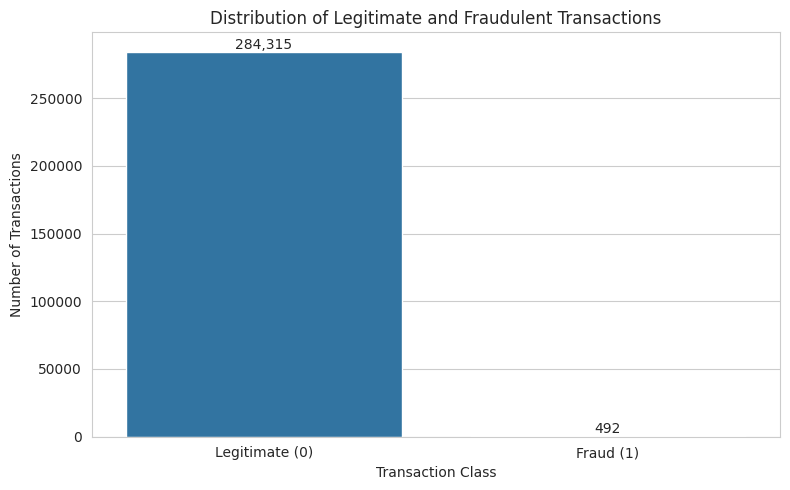

In [20]:
# Plot the number of legitimate and fraudulent transactions.
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

# Add count labels above the bars.
for i, value in enumerate(class_counts.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])

plt.tight_layout()
plt.show()

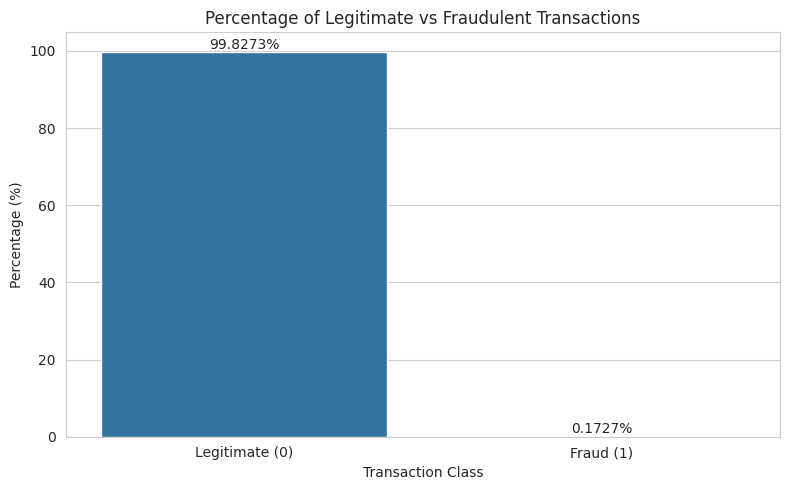

In [21]:
# Plot the percentage of each target class.
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_percentage.index,
    y=class_percentage.values
)

for i, value in enumerate(class_percentage.values):
    ax.text(i, value, f"{value:.4f}%", ha="center", va="bottom")

plt.title("Percentage of Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Percentage (%)")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])

plt.tight_layout()
plt.show()

### EDA Observation — Class Imbalance

The fraud class is extremely small compared with the legitimate class.

Therefore, **accuracy must not be our primary evaluation metric**. Later we will focus on precision, recall, F1-score, ROC-AUC, PR-AUC, and confusion matrices.

We will also compare class-weighting, undersampling, SMOTE, and other imbalance-handling approaches.

## 10. EDA — Transaction Amount

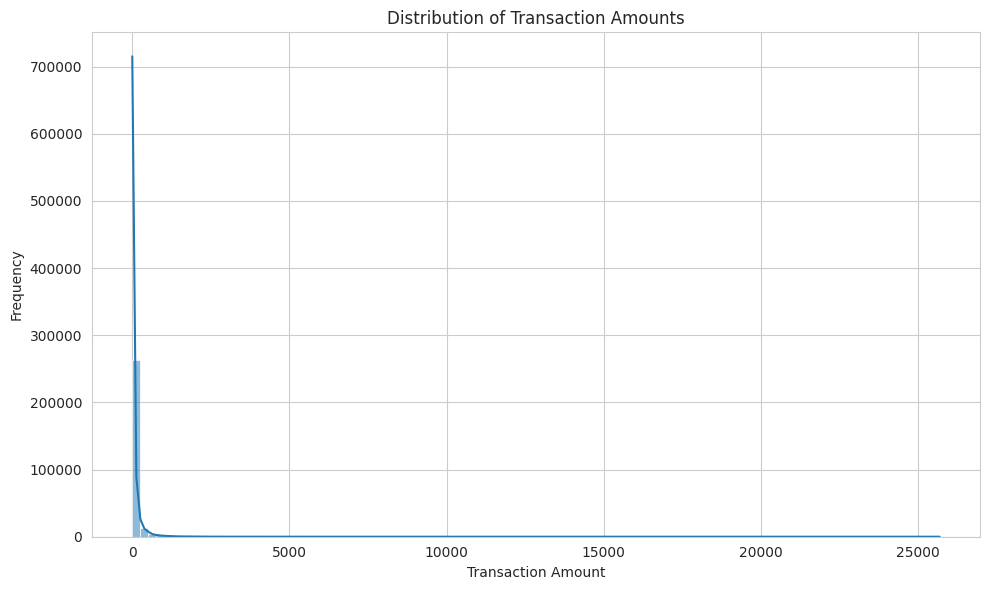

In [22]:
# Distribution of transaction amounts.
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Amount",
    bins=100,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

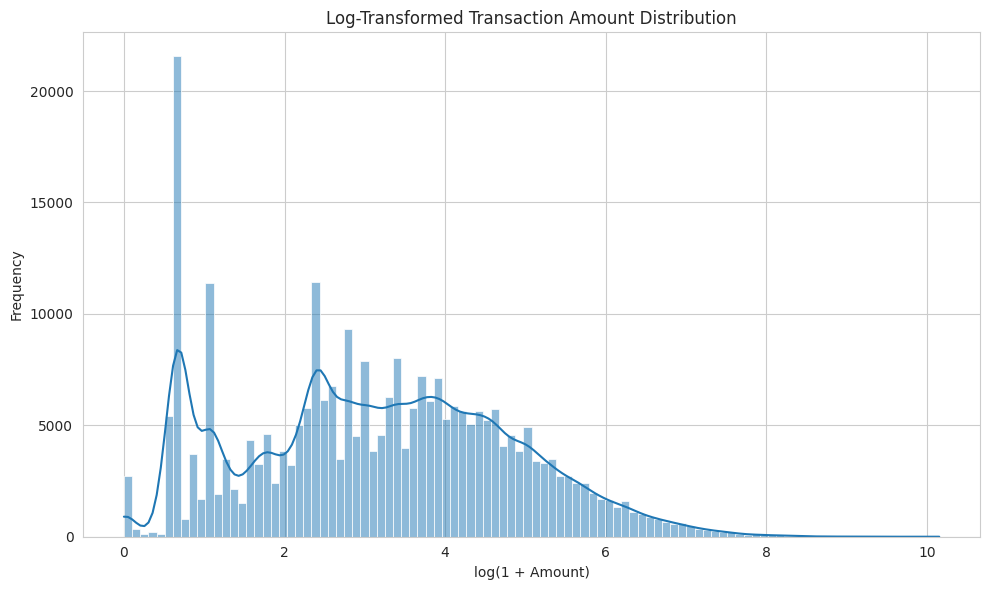

In [23]:
# Create a log-transformed Amount column for EDA.
# log1p(x) = log(1 + x), so Amount = 0 is handled safely.
df["Amount_Log"] = np.log1p(df["Amount"])

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Amount_Log",
    bins=100,
    kde=True
)

plt.title("Log-Transformed Transaction Amount Distribution")
plt.xlabel("log(1 + Amount)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

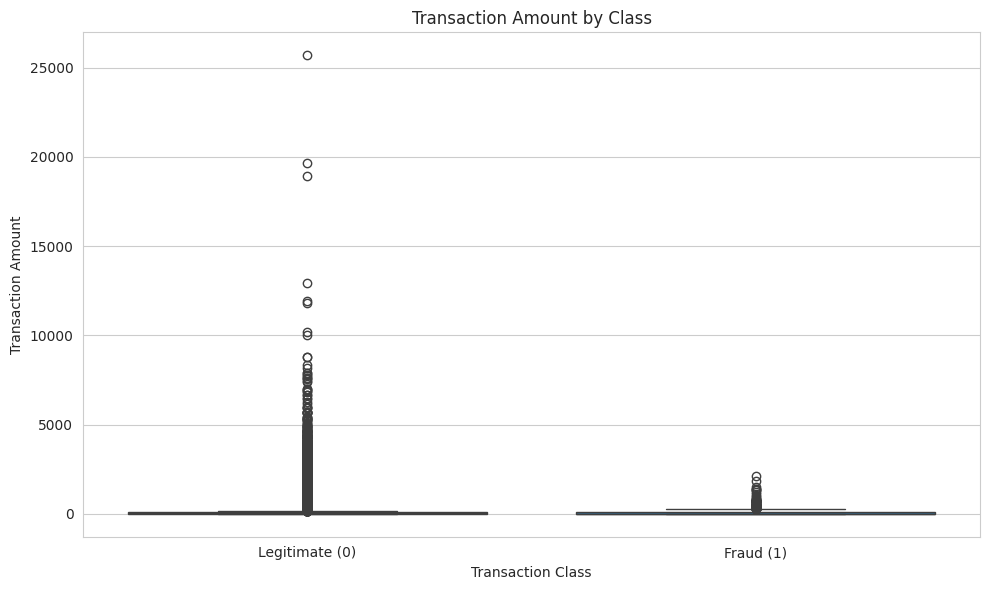

In [24]:
# Compare transaction amount between legitimate and fraudulent transactions.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])

plt.tight_layout()
plt.show()

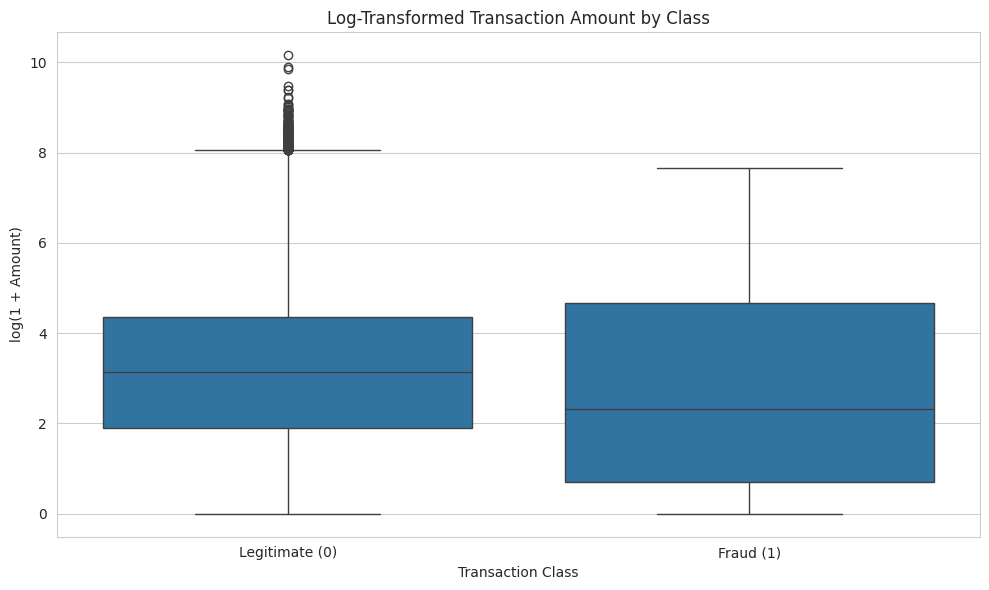

In [25]:
# Compare log-transformed transaction amount by class.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount_Log"
)

plt.title("Log-Transformed Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("log(1 + Amount)")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])

plt.tight_layout()
plt.show()

In [26]:
# Numerical comparison of transaction amount by class.
amount_by_class = df.groupby("Class")["Amount"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

amount_by_class

,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.291022,22.00,250.105092,0.0,25691.16
1,492,122.211321,9.25,256.683288,0.0,2125.87


## 11. EDA — Transaction Time

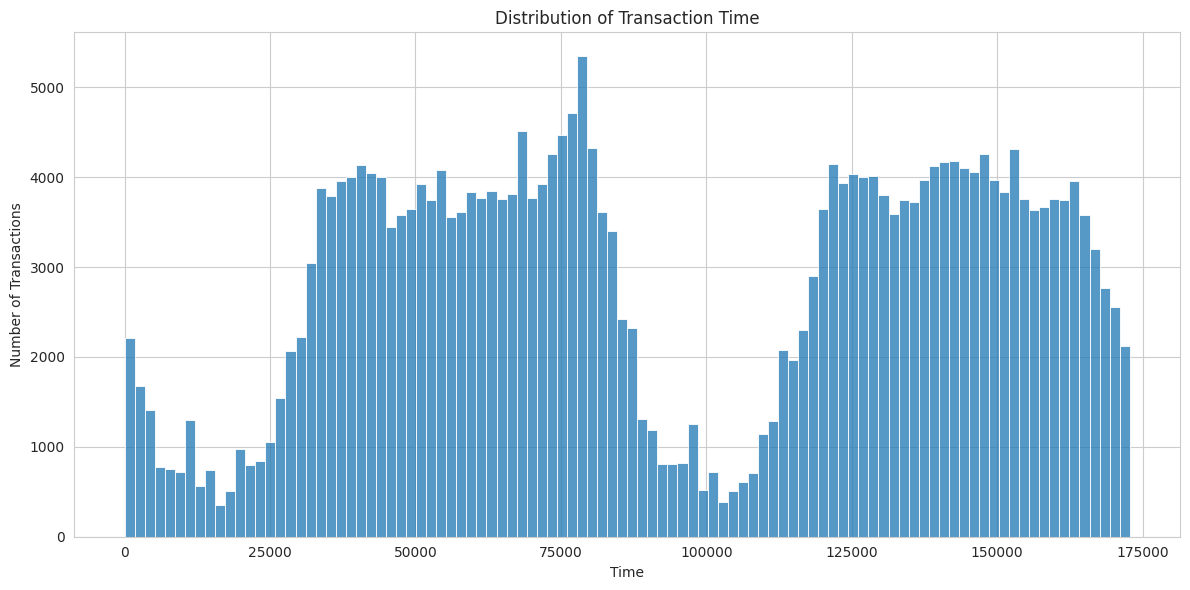

In [27]:
# Overall distribution of transaction time.
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Time",
    bins=100
)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

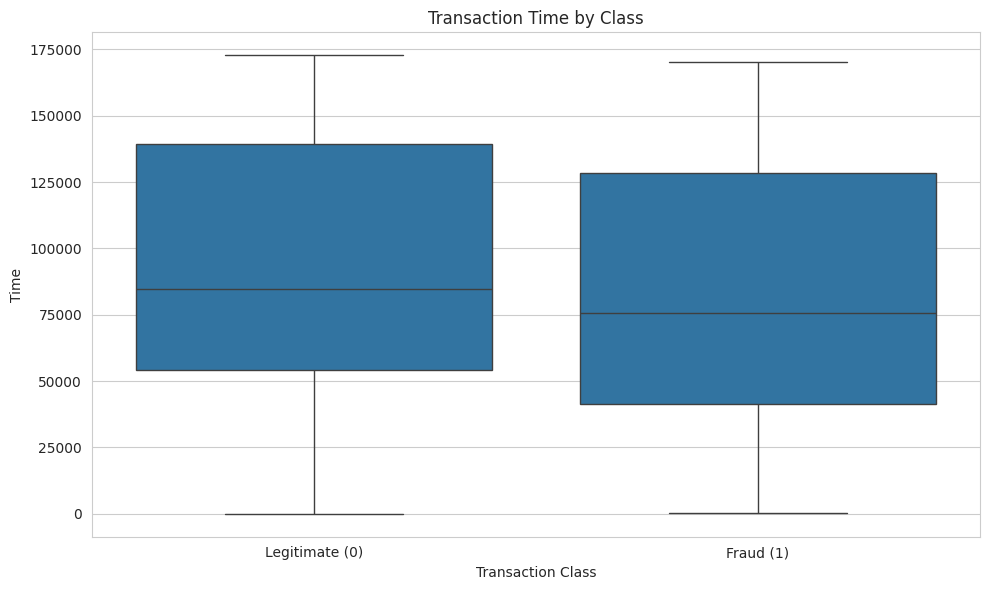

In [28]:
# Compare transaction time between the two classes.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Time"
)

plt.title("Transaction Time by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Time")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])

plt.tight_layout()
plt.show()

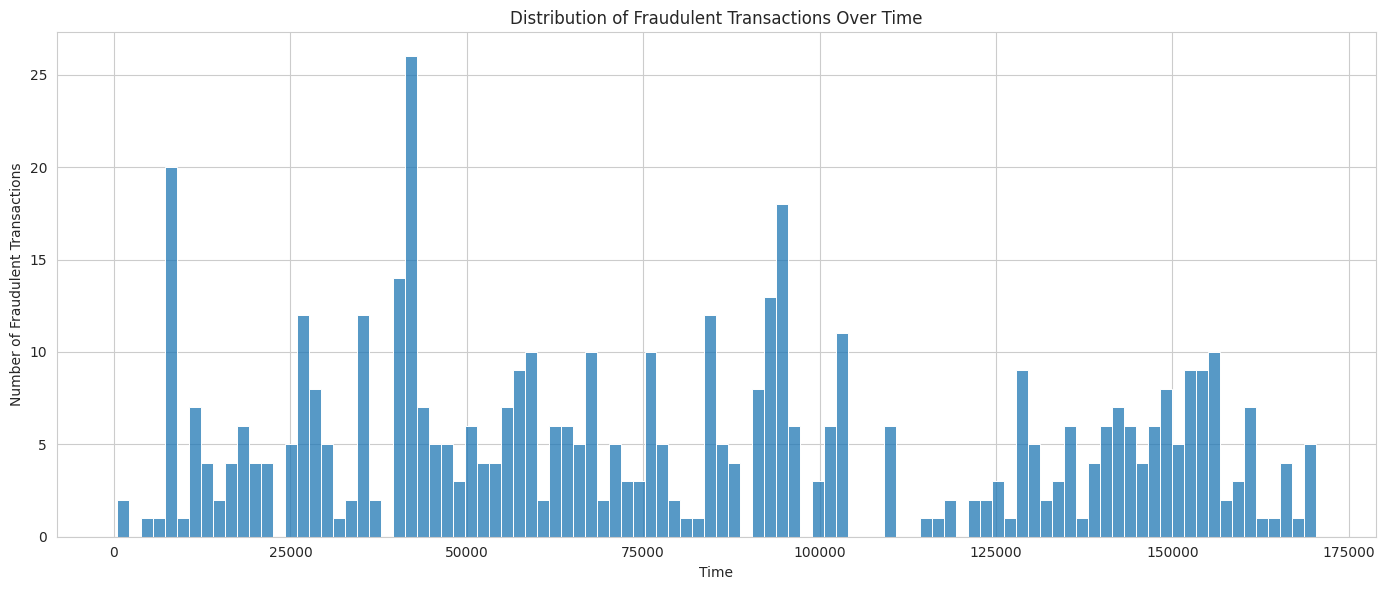

In [29]:
# Select fraudulent transactions.
fraud_df = df[df["Class"] == 1]

# Plot fraud transactions over time.
plt.figure(figsize=(14, 6))

sns.histplot(
    data=fraud_df,
    x="Time",
    bins=100
)

plt.title("Distribution of Fraudulent Transactions Over Time")
plt.xlabel("Time")
plt.ylabel("Number of Fraudulent Transactions")

plt.tight_layout()
plt.show()

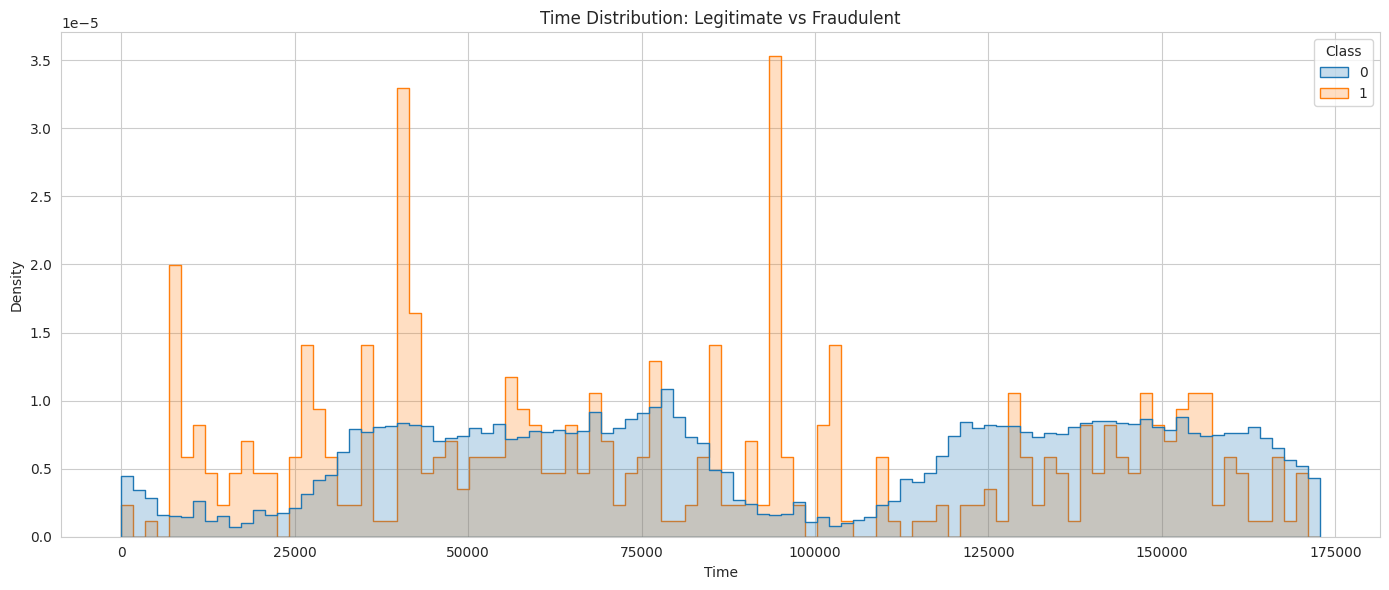

In [30]:
# Compare time distributions using density.
plt.figure(figsize=(14, 6))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Time Distribution: Legitimate vs Fraudulent")
plt.xlabel("Time")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

## 12. EDA — V1 to V28 Feature Distributions

In [31]:
# Identify the anonymized V1-V28 features automatically.
v_features = [col for col in df.columns if col.startswith("V")]

print(f"Number of V features: {len(v_features)}")
print(v_features)

Number of V features: 28
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28']


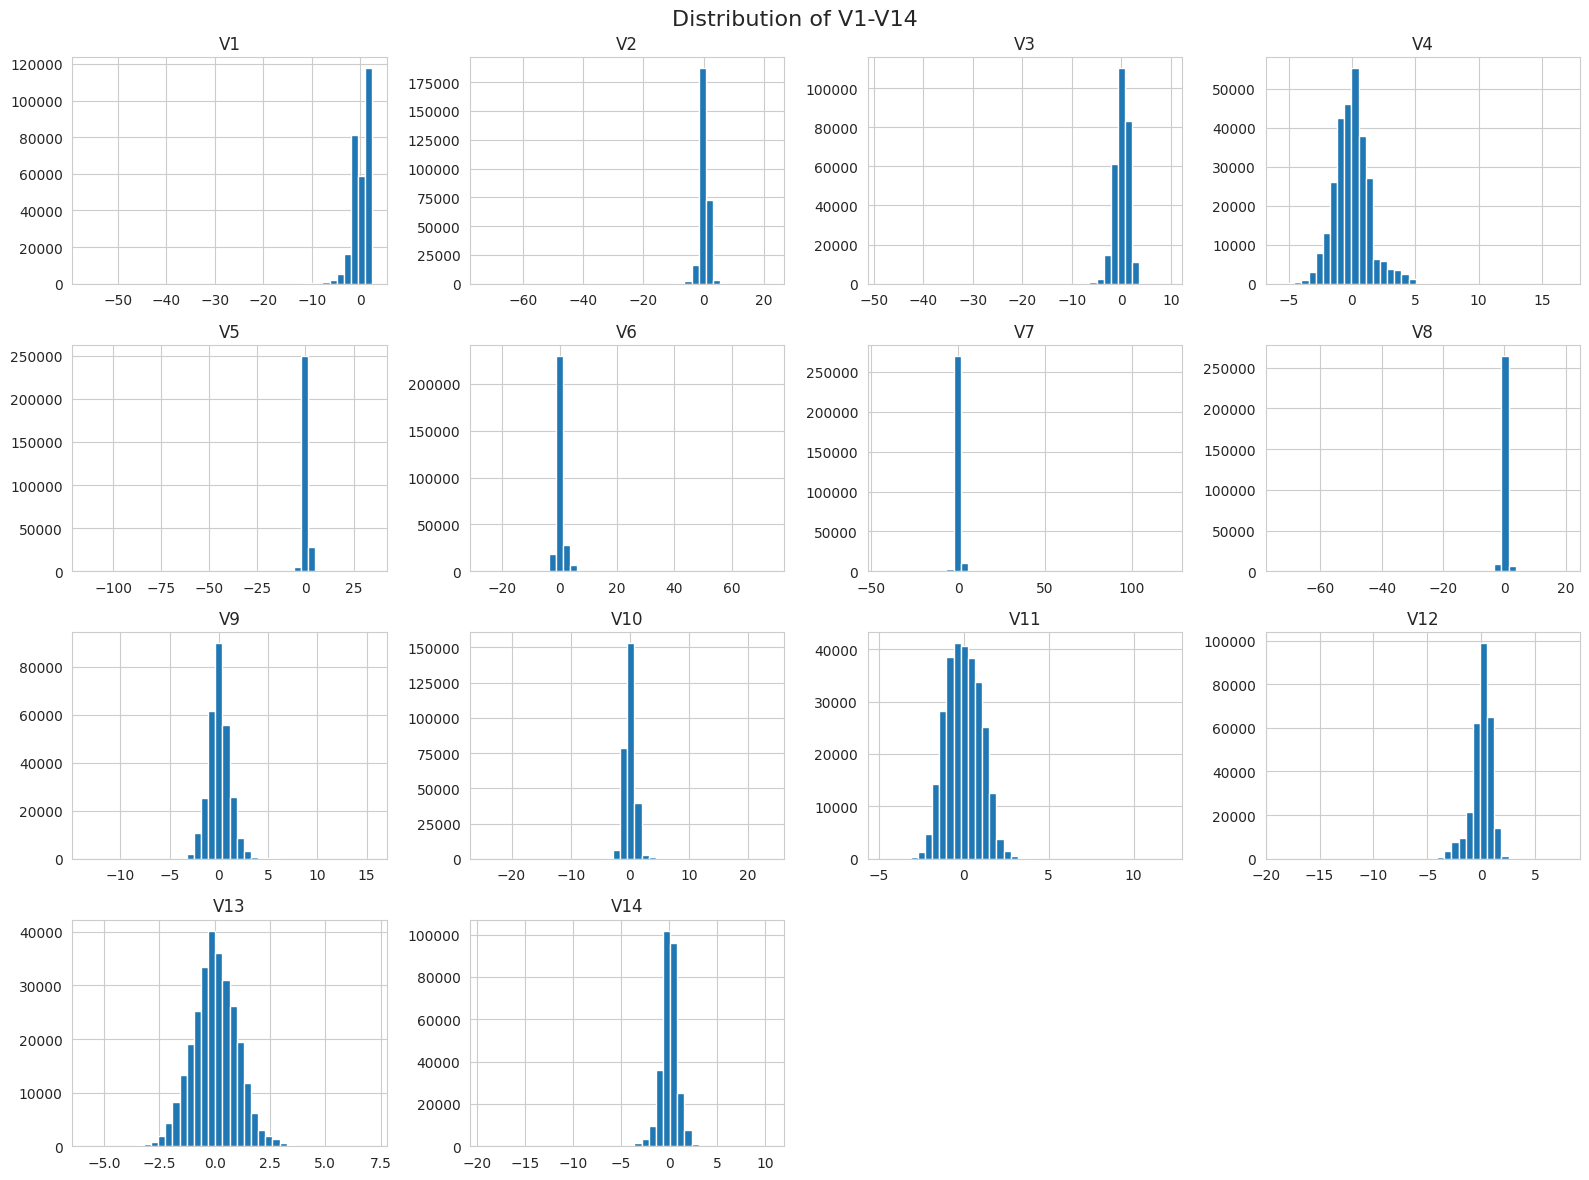

In [32]:
# Plot distributions for V1-V14.
features_batch_1 = v_features[:14]

df[features_batch_1].hist(
    bins=40,
    figsize=(16, 12)
)

plt.suptitle("Distribution of V1-V14", fontsize=16)
plt.tight_layout()
plt.show()

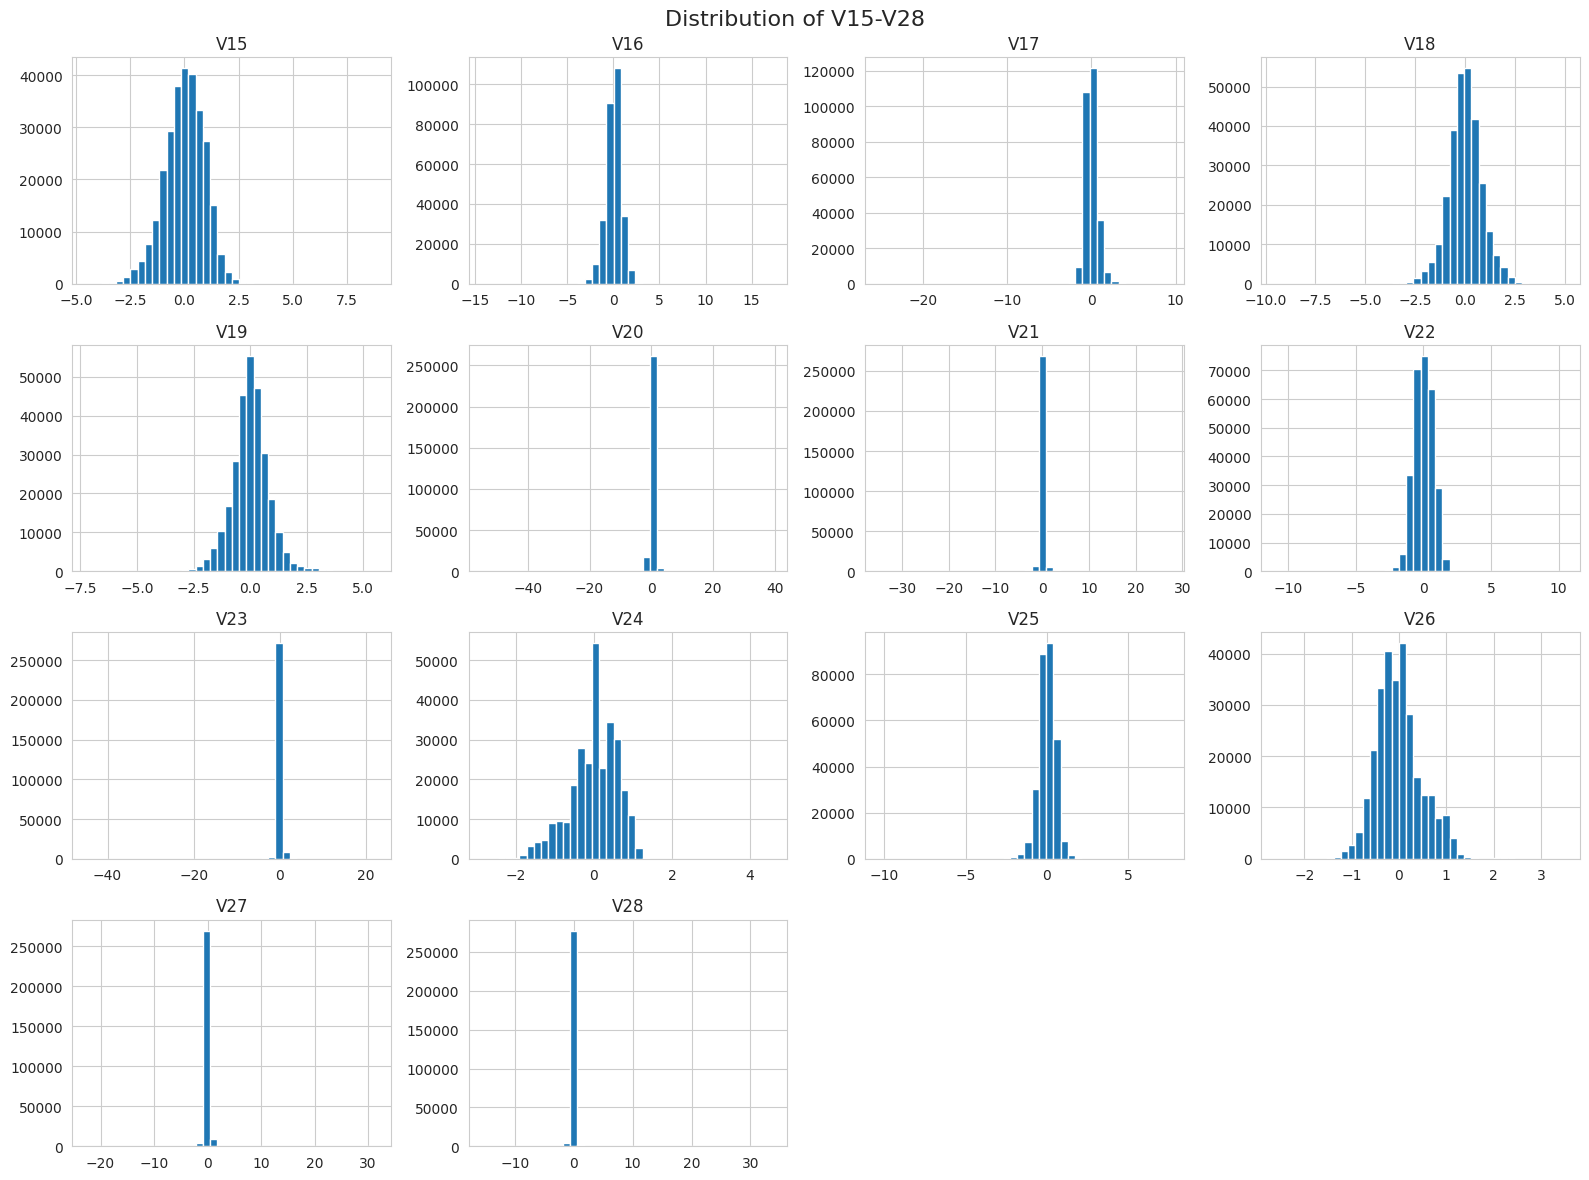

In [33]:
# Plot distributions for V15-V28.
features_batch_2 = v_features[14:]

df[features_batch_2].hist(
    bins=40,
    figsize=(16, 12)
)

plt.suptitle("Distribution of V15-V28", fontsize=16)
plt.tight_layout()
plt.show()

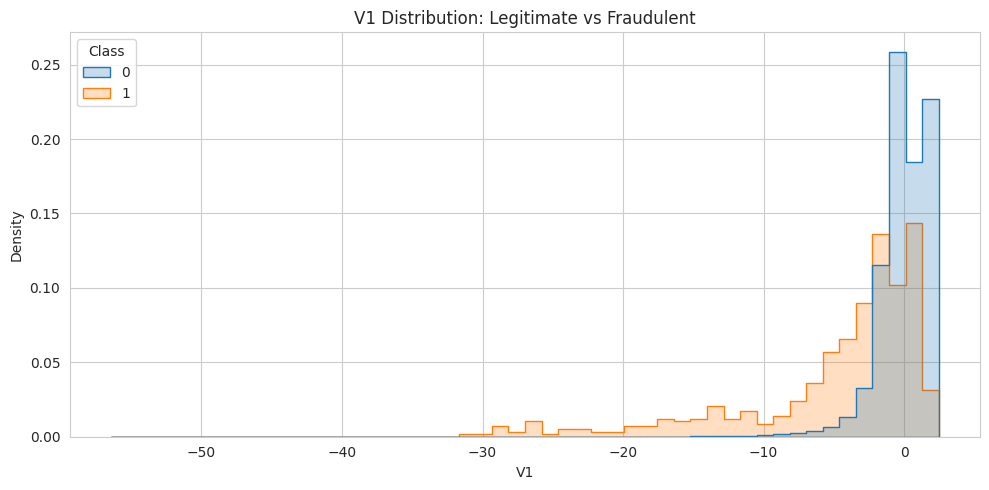

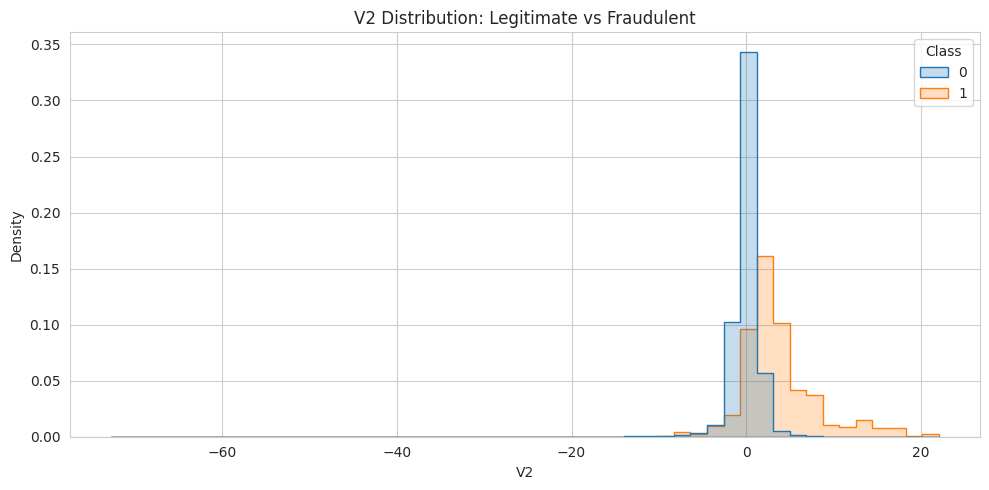

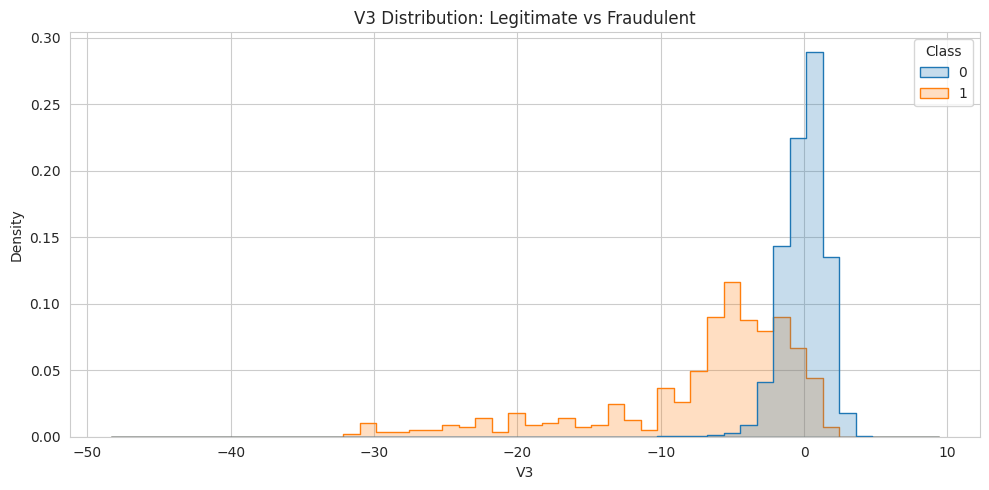

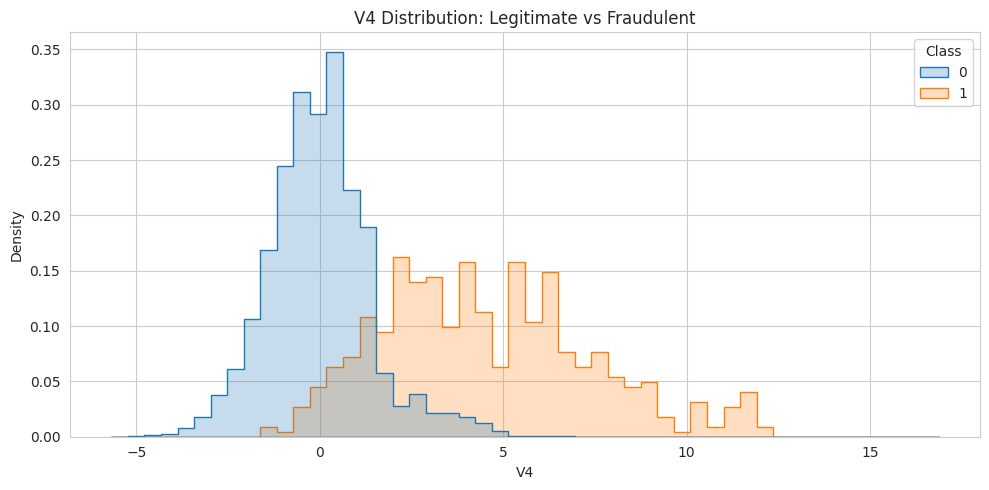

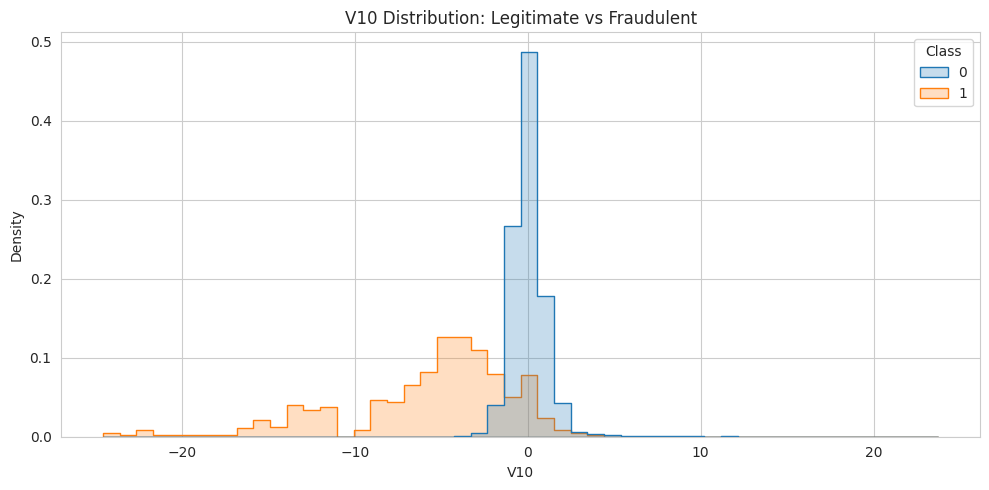

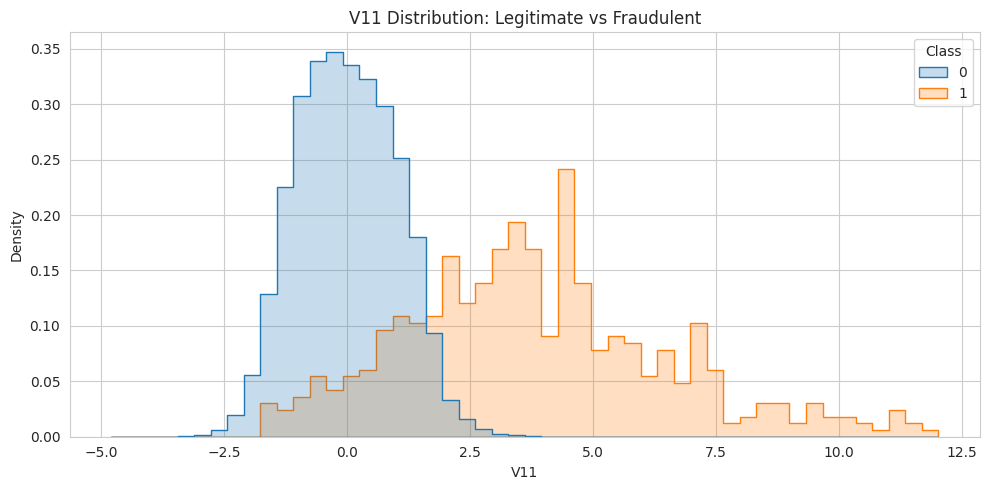

In [34]:
# Compare selected features between legitimate and fraudulent transactions.
selected_features = ["V1", "V2", "V3", "V4", "V10", "V11"]

for feature in selected_features:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x=feature,
        hue="Class",
        bins=50,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"{feature} Distribution: Legitimate vs Fraudulent")
    plt.xlabel(feature)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

## 13. EDA — Correlation Analysis

In [35]:
# Calculate the Pearson correlation matrix.
correlation_matrix = df.corr(numeric_only=True)

correlation_matrix.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Amount_Log
Time,1.000000,1.173963e-01,-1.059333e-02,-4.196182e-01,-1.052602e-01,1.730721e-01,-6.301647e-02,8.471437e-02,-3.694943e-02,-8.660434e-03,3.061663e-02,-2.476894e-01,1.243481e-01,-6.590202e-02,-9.875682e-02,-1.834533e-01,1.190287e-02,-7.329721e-02,9.043813e-02,2.897530e-02,-5.086602e-02,4.473573e-02,1.440591e-01,5.114236e-02,-1.618187e-02,-2.330828e-01,-4.140710e-02,-5.134591e-03,-9.412688e-03,-0.010596,-0.012323,-0.028515
V1,0.117396,1.000000e+00,4.135835e-16,-1.227819e-15,-9.215150e-16,1.812612e-17,-6.506567e-16,-1.005191e-15,-2.433822e-16,-1.513678e-16,7.388135e-17,2.125498e-16,2.053457e-16,-2.425603e-17,-5.020280e-16,3.547782e-16,7.212815e-17,-3.879840e-16,3.230206e-17,1.502024e-16,4.654551e-16,-2.457409e-16,-4.290944e-16,6.168652e-16,-4.425156e-17,-9.605737e-16,-1.581290e-17,1.198124e-16,2.083082e-15,-0.227709,-0.101347,-0.096375
V2,-0.010593,4.135835e-16,1.000000e+00,3.243764e-16,-1.121065e-15,5.157519e-16,2.787346e-16,2.055934e-16,-5.377041e-17,1.978488e-17,-3.991394e-16,1.975426e-16,-9.568710e-17,6.295388e-16,-1.730566e-16,-4.995814e-17,1.177316e-17,-2.685296e-16,3.284605e-16,-7.118719e-18,2.506675e-16,-8.480447e-17,1.526333e-16,1.634231e-16,1.247925e-17,-4.478846e-16,2.057310e-16,-4.966953e-16,-5.093836e-16,-0.531409,0.091289,-0.450317
V3,-0.419618,-1.227819e-15,3.243764e-16,1.000000e+00,4.711293e-16,-6.539009e-17,1.627627e-15,4.895305e-16,-1.268779e-15,5.568367e-16,1.156587e-15,1.576830e-15,6.310231e-16,2.807652e-16,4.739859e-16,9.068793e-16,8.299445e-16,7.614712e-16,1.509897e-16,3.463522e-16,-9.316409e-16,5.706192e-17,-1.133902e-15,-4.983035e-16,2.686834e-19,-1.104734e-15,-1.238062e-16,1.045747e-15,9.775546e-16,-0.210880,-0.192961,-0.033913
V4,-0.105260,-9.215150e-16,-1.121065e-15,4.711293e-16,1.000000e+00,-1.719944e-15,-7.491959e-16,-4.104503e-16,5.697192e-16,6.923247e-16,2.232685e-16,3.459380e-16,-5.625518e-16,1.303306e-16,2.282280e-16,1.377649e-16,-9.614528e-16,-2.699612e-16,-5.103644e-16,-3.980557e-16,-1.857247e-16,-1.949553e-16,-6.276051e-17,9.164206e-17,1.584638e-16,6.070716e-16,-4.247268e-16,3.977061e-17,-2.761403e-18,0.098732,0.133447,-0.004677


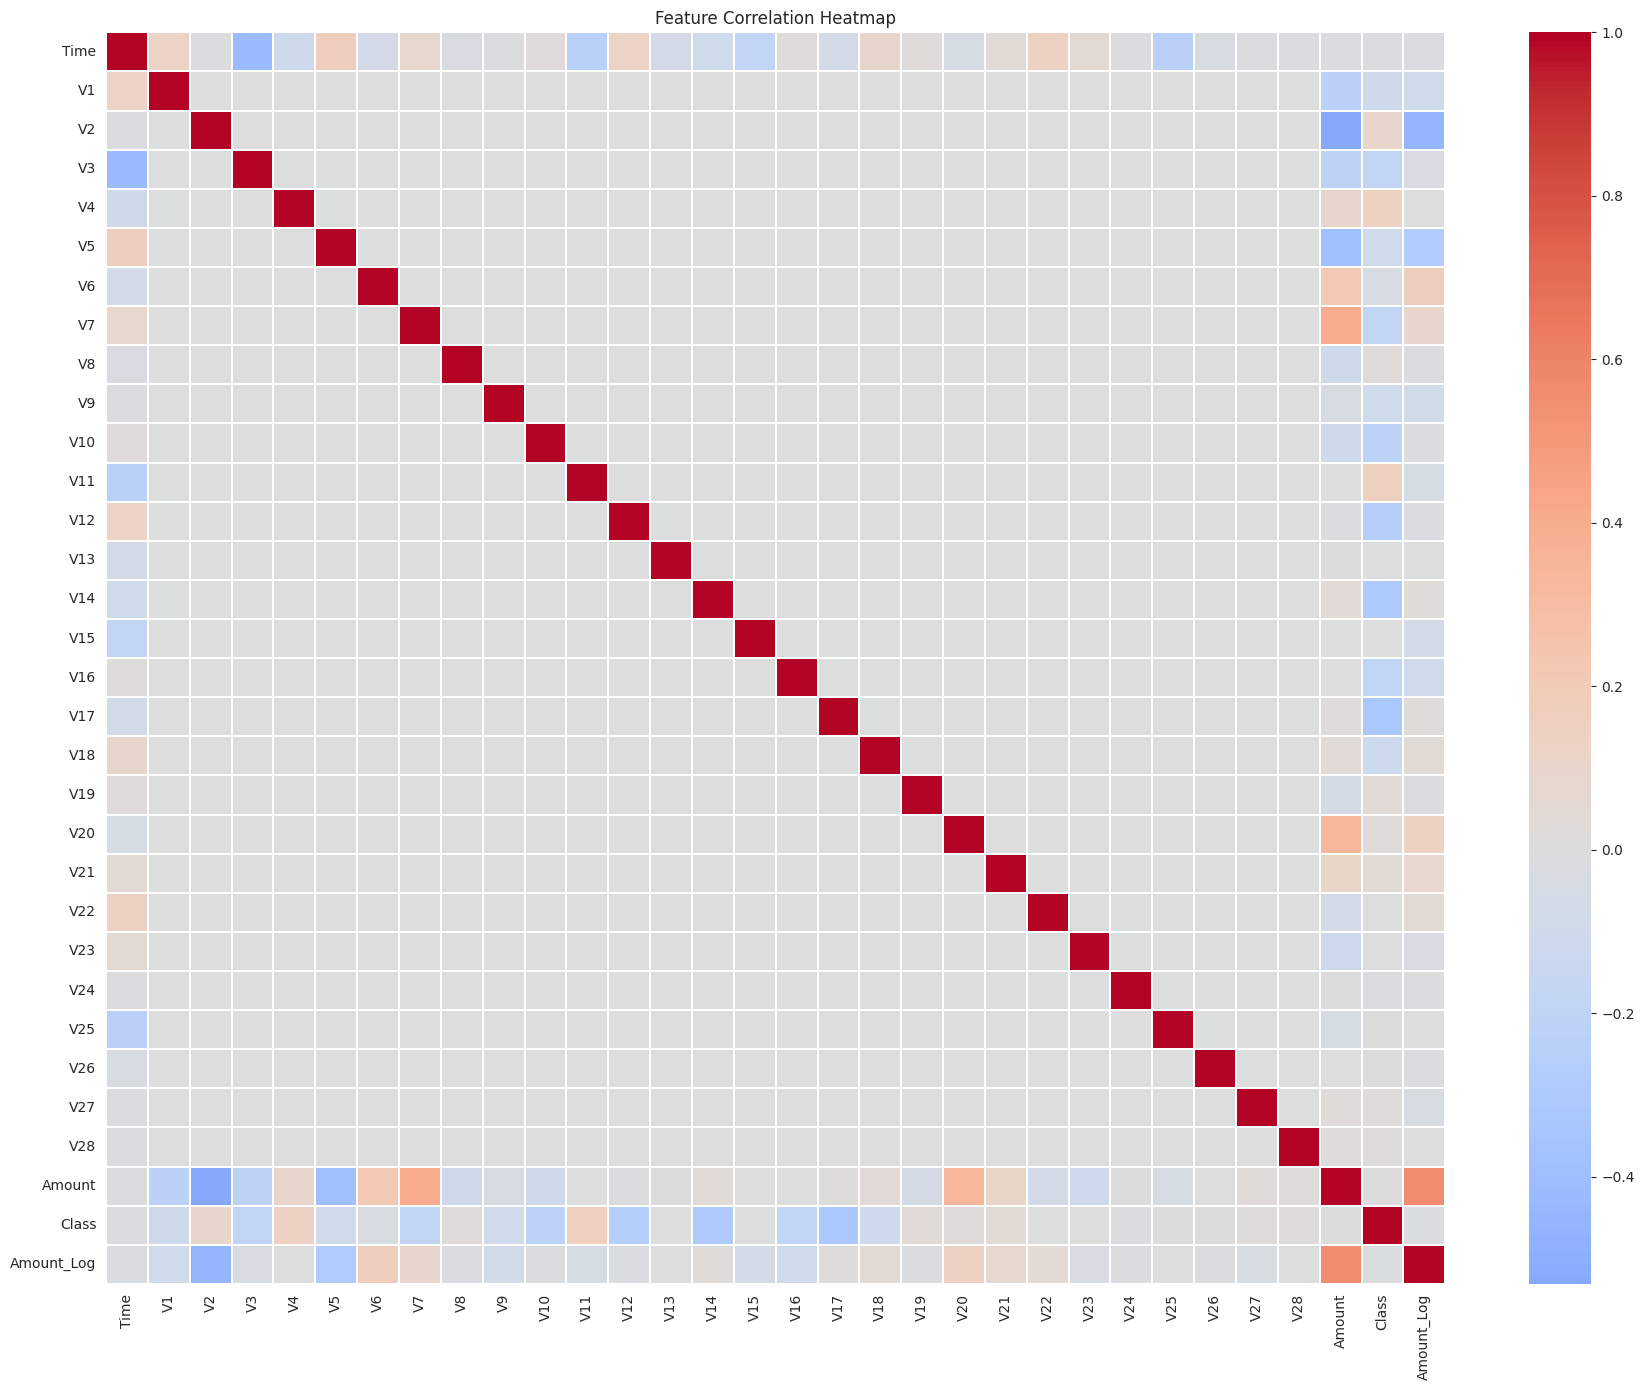

In [36]:
# Visualize the correlation matrix.
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

In [37]:
# Sort features by their correlation with the target.
target_correlation = correlation_matrix["Class"].sort_values(
    ascending=False
)

target_correlation

Class         1.000000
V11           0.154876
V4            0.133447
V2            0.091289
V21           0.040413
V19           0.034783
V20           0.020090
V8            0.019875
V27           0.017580
V28           0.009536
Amount        0.005632
V26           0.004455
V25           0.003308
V22           0.000805
V23          -0.002685
V15          -0.004223
V13          -0.004570
V24          -0.007221
Amount_Log   -0.008326
Time         -0.012323
V6           -0.043643
V5           -0.094974
V9           -0.097733
V1           -0.101347
V18          -0.111485
V7           -0.187257
V3           -0.192961
V16          -0.196539
V10          -0.216883
V12          -0.260593
V14          -0.302544
V17          -0.326481
Name: Class, dtype: float64

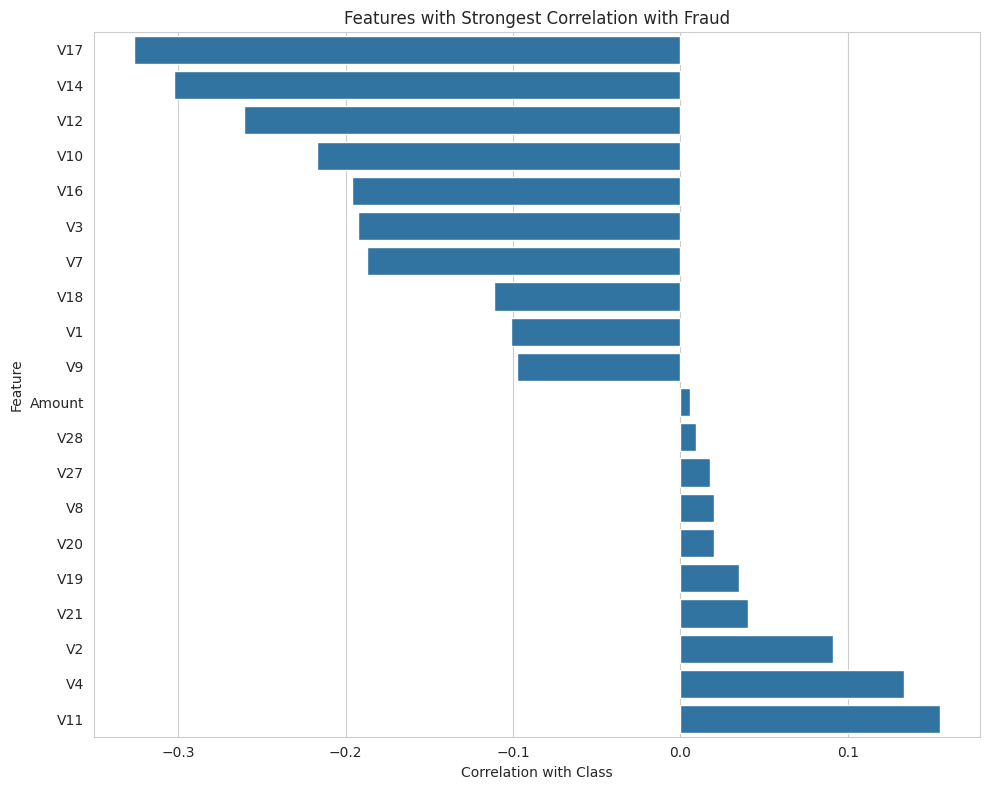

In [38]:
# Visualize the strongest positive and negative target correlations.
target_corr_without_class = target_correlation.drop("Class")

top_positive = target_corr_without_class.head(10)
top_negative = target_corr_without_class.tail(10)

top_correlations = pd.concat([
    top_positive,
    top_negative
]).sort_values()

plt.figure(figsize=(10, 8))

sns.barplot(
    x=top_correlations.values,
    y=top_correlations.index
)

plt.title("Features with Strongest Correlation with Fraud")
plt.xlabel("Correlation with Class")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## 14. EDA — Outlier Analysis

In [39]:
# Detect statistical outliers using the IQR method.

numeric_features = df.select_dtypes(
    include=np.number
).columns

outlier_summary = []

for feature in numeric_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

outlier_summary_df = outlier_summary_df.sort_values(
    by="Outlier Count",
    ascending=False
)

outlier_summary_df.head(15)

,Feature,Q1,Q3,IQR,Outlier Count,Outlier Percentage
27,V27,-0.070840,0.091045,0.161885,39163,13.750715
29,Amount,5.600000,77.165000,71.565000,31904,11.201972
28,V28,-0.052960,0.078280,0.131240,30342,10.653530
20,V20,-0.211721,0.133041,0.344762,27770,9.750463
8,V8,-0.208630,0.327346,0.535976,24134,8.473809
6,V6,-0.768296,0.398565,1.166861,22965,8.063355
23,V23,-0.161846,0.147642,0.309488,18541,6.510023
12,V12,-0.405571,0.618238,1.023810,15348,5.388912
21,V21,-0.228395,0.186377,0.414772,14497,5.090114
14,V14,-0.425574,0.493150,0.918724,14149,4.967926


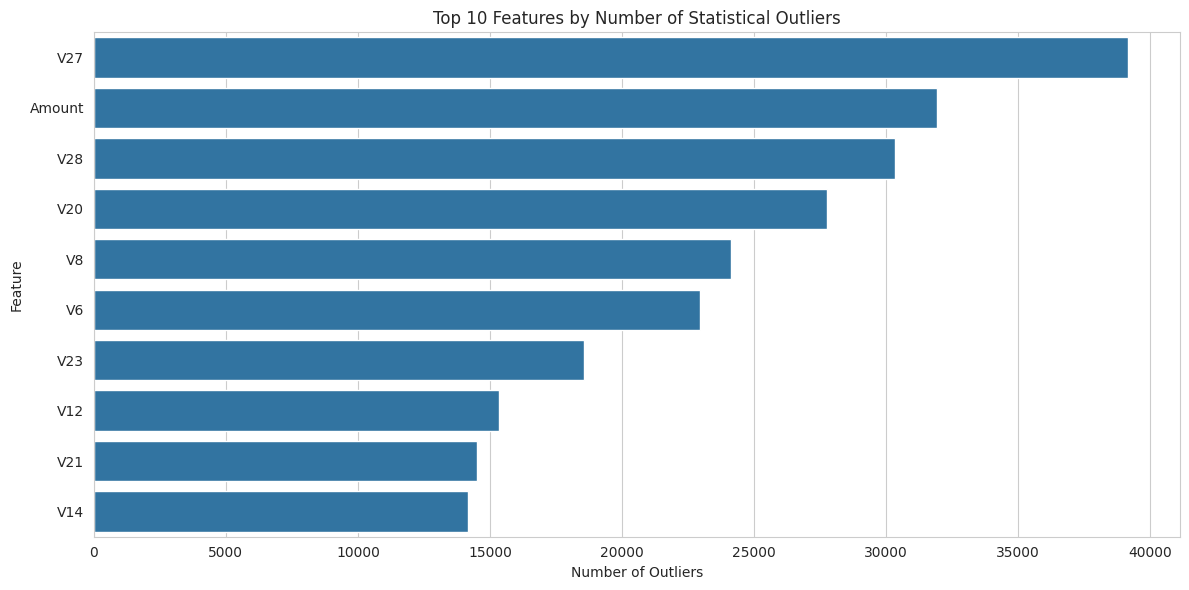

In [40]:
# Visualize the ten features with the most statistical outliers.
plt.figure(figsize=(12, 6))

sns.barplot(
    data=outlier_summary_df.head(10),
    x="Outlier Count",
    y="Feature"
)

plt.title("Top 10 Features by Number of Statistical Outliers")
plt.xlabel("Number of Outliers")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## 15. Fraud vs. Legitimate Feature Statistics

In [41]:
# Compare mean feature values between the two classes.
mean_by_class = df.groupby("Class").mean(numeric_only=True).T

mean_by_class.columns = [
    "Legitimate_Mean",
    "Fraud_Mean"
]

mean_by_class["Absolute_Difference"] = (
    mean_by_class["Fraud_Mean"] -
    mean_by_class["Legitimate_Mean"]
).abs()

mean_by_class.sort_values(
    "Absolute_Difference",
    ascending=False
).head(15)

,Legitimate_Mean,Fraud_Mean,Absolute_Difference
Time,94838.202258,80746.806911,14091.395347
Amount,88.291022,122.211321,33.920299
V3,0.012171,-7.033281,7.045452
V14,0.012064,-6.971723,6.983787
V17,0.011535,-6.665836,6.677371
V12,0.010832,-6.259393,6.270225
V10,0.009824,-5.676883,5.686707
V7,0.009637,-5.568731,5.578368
V1,0.008258,-4.771948,4.780206
V4,-0.007860,4.542029,4.549889


In [42]:
# Detailed transaction amount comparison.
amount_comparison = df.groupby("Class")["Amount"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std="std",
    Minimum="min",
    Maximum="max"
)

amount_comparison.index = ["Legitimate", "Fraud"]

amount_comparison

,Count,Mean,Median,Std,Minimum,Maximum
Legitimate,284315,88.291022,22.00,250.105092,0.0,25691.16
Fraud,492,122.211321,9.25,256.683288,0.0,2125.87


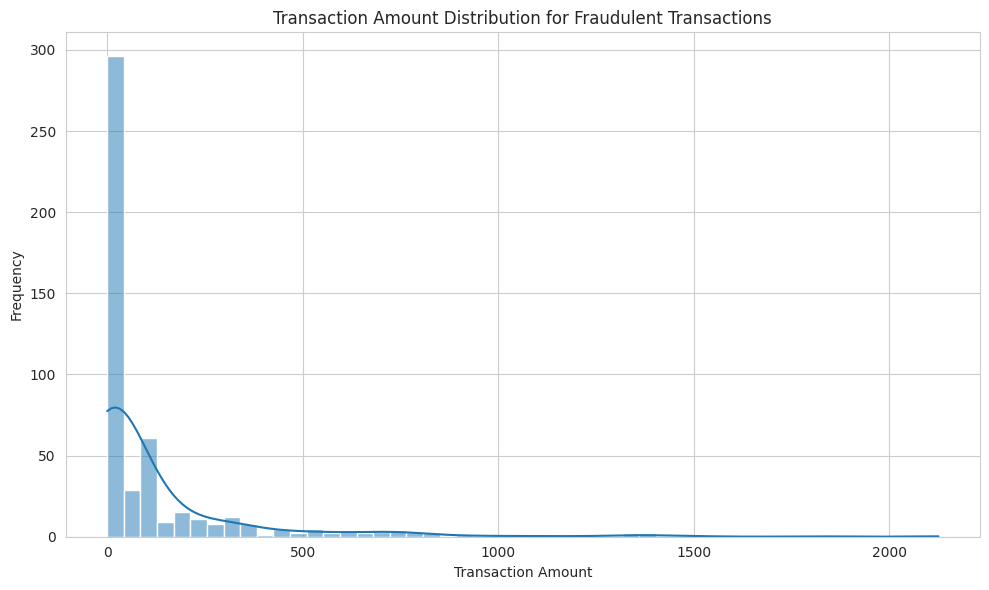

In [43]:
# Distribution of transaction amounts for fraud cases only.
plt.figure(figsize=(10, 6))

sns.histplot(
    fraud_df["Amount"],
    bins=50,
    kde=True
)

plt.title("Transaction Amount Distribution for Fraudulent Transactions")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 16. Final EDA Summary

In [44]:
# ============================================================
# FINAL EDA SUMMARY
# ============================================================

# Exclude the target and the EDA-only Amount_Log column.
feature_count = len([
    col for col in df.columns
    if col not in ["Class", "Amount_Log"]
])

print("=" * 70)
print("EDA SUMMARY")
print("=" * 70)

print(f"Total transactions       : {len(df):,}")
print(f"Total original features : {feature_count:,}")
print(f"Legitimate transactions  : {(df['Class'] == 0).sum():,}")
print(f"Fraudulent transactions  : {(df['Class'] == 1).sum():,}")
print(f"Fraud percentage         : {(df['Class'] == 1).mean() * 100:.4f}%")
print(f"Missing values           : {df.isnull().sum().sum():,}")
print(f"Duplicate rows           : {df.duplicated().sum():,}")

print("=" * 70)

EDA SUMMARY
Total transactions       : 284,807
Total original features : 30
Legitimate transactions  : 284,315
Fraudulent transactions  : 492
Fraud percentage         : 0.1727%
Missing values           : 0
Duplicate rows           : 1,081


# EDA Conclusions

### Main findings

- The dataset is **highly imbalanced**.
- Accuracy alone will not be an appropriate primary metric.
- Transaction `Amount` is strongly skewed.
- `Time` may contain useful temporal information.
- `V1`–`V28` have different distributions and relationships with the fraud target.
- Correlation gives an initial view of potentially useful features, but correlation alone is not enough for feature selection.
- Statistical outliers should not automatically be removed because unusual transactions may represent fraud.
- The next stage must use a **leakage-safe train/validation/test split**.

### Next stage

**Data Preprocessing & Modeling**

I will build:
- Train/validation/test split
- Scaling
- Baseline models
- Class weighting
- Random undersampling
- SMOTE / SMOTETomek
- Random Forest
- XGBoost
- LightGBM
- CatBoost
- Neural Network
- Hyperparameter tuning
- Hybrid/stacking ensemble
- Threshold optimization
- SHAP explainability
- Error analysis